In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=DeprecationWarning)  
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

os.makedirs("data/processed", exist_ok=True)
os.makedirs("images", exist_ok=True)

print("Environment ready. Output folders verified.")

Environment ready. Output folders verified.


In [3]:
df_raw = pd.read_csv("../CSE13/data/raw/healthcare_data.csv")

print(f"Loaded file: {"../CSE13/data/raw/healthcare_data.csv"}")
print(f"Raw dataset shape: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
display(df_raw.head())

Loaded file: ../CSE13/data/raw/healthcare_data.csv
Raw dataset shape: 255 rows × 12 columns


,Patient_ID,Visit_Date,City,Age,Department,Admission_Type,Wait_Time_Minutes,Consultation_Minutes,Doctor_Experience_Years,Bill_Amount_INR,Satisfaction_Score,Insurance_Type
0,P1001,2026-01-01,bengaluru,47,Orthopedics,Planned,33.0,18,18.0,2500.0,10,Government
1,P1002,2026-01-02,Bengaluru,51,General Medicine,Walk-In,74.0,13,13.0,680.0,5,Government
2,P1003,2026-01-04,delhi,63,Cardiology,Emergency,9.0,21,23.0,3210.0,5,NaN
3,P1004,2026-01-05,Bengaluru,32,Cardiology,Walk-In,44.0,29,26.0,3190.0,8,Self-Pay
4,P1005,2026-01-06,Mumbai,65,General Medicine,Walk-In,25.0,30,7.0,1050.0,4,Private


In [4]:
print("--- Column Data Types ---")
print(df_raw.dtypes)

print("\n--- Missing Values per Column ---")
missing_summary = pd.DataFrame({
    "Missing_Count": df_raw.isnull().sum(),
    "Missing_Pct (%)": (df_raw.isnull().mean() * 100).round(2)
})
print(missing_summary[missing_summary["Missing_Count"] > 0])

print(f"\nExact duplicate rows: {df_raw.duplicated().sum()}")
print(f"Unique Patient_IDs: {df_raw['Patient_ID'].nunique()} out of {len(df_raw)} rows")

print("\n--- Unique City Values (Before Cleaning) ---")
print(df_raw["City"].value_counts(dropna=False))

print("\n--- Impossible Age Values (< 0 or > 110) ---")
display(df_raw[(df_raw["Age"] < 0) | (df_raw["Age"] > 110)])

print("\n--- Numeric Summary Statistics (Raw Data) ---")
display(df_raw.describe().round(2))

--- Column Data Types ---
Patient_ID                     str
Visit_Date                     str
City                           str
Age                          int64
Department                     str
Admission_Type                 str
Wait_Time_Minutes          float64
Consultation_Minutes         int64
Doctor_Experience_Years    float64
Bill_Amount_INR            float64
Satisfaction_Score           int64
Insurance_Type                 str
dtype: object

--- Missing Values per Column ---
                         Missing_Count  Missing_Pct (%)
Wait_Time_Minutes                    6             2.35
Doctor_Experience_Years              5             1.96
Bill_Amount_INR                      5             1.96
Insurance_Type                       5             1.96

Exact duplicate rows: 5
Unique Patient_IDs: 250 out of 255 rows

--- Unique City Values (Before Cleaning) ---
City
Mumbai       54
Pune         53
Bengaluru    42
Delhi        42
Lucknow      42
Mumbai        4
bengaluru    

,Patient_ID,Visit_Date,City,Age,Department,Admission_Type,Wait_Time_Minutes,Consultation_Minutes,Doctor_Experience_Years,Bill_Amount_INR,Satisfaction_Score,Insurance_Type
30,P1030,2026-02-15,Mumbai,187,Cardiology,Emergency,5.0,11,5.0,3810.0,7,Private
57,P1057,2026-03-24,Lucknow,-4,Cardiology,Planned,66.0,17,15.0,1490.0,5,Private



--- Numeric Summary Statistics (Raw Data) ---


,Age,Wait_Time_Minutes,Consultation_Minutes,Doctor_Experience_Years,Bill_Amount_INR,Satisfaction_Score
count,255.00,249.00,255.00,250.00,250.00,255.00
mean,38.22,40.09,17.53,15.96,1682.60,6.59
std,23.01,26.12,6.44,8.36,938.08,2.01
min,-4.00,5.00,5.00,2.00,450.00,1.00
25%,21.00,21.00,13.00,8.00,960.00,5.00
50%,37.00,36.00,18.00,17.00,1485.00,7.00
75%,55.00,55.00,21.00,23.00,2330.00,8.00
max,187.00,119.00,41.00,30.00,4740.00,10.00


In [ ]:
df = df_raw.copy()


df = df.drop_duplicates(keep="first").reset_index(drop=True)
print(f"Rows after removing duplicates: {len(df)}")


df["City"] = df["City"].astype(str).str.strip().str.title()
print("\nStandardised City counts:")
print(df["City"].value_counts())


invalid_age_mask = (df["Age"] < 0) | (df["Age"] > 110)
print(f"\nInvalid ages replaced with NaN: {invalid_age_mask.sum()}")
df.loc[invalid_age_mask, "Age"] = np.nan
median_age = df["Age"].median()
df["Age"] = df["Age"].fillna(median_age).astype(int)
print(f"Imputed invalid ages with median Age: {int(median_age)}")


df["Insurance_Type"] = df["Insurance_Type"].fillna("Unknown")

for col in ["Wait_Time_Minutes", "Doctor_Experience_Years", "Bill_Amount_INR"]:
    med_val = df[col].median()
    missing_cnt = df[col].isnull().sum()
    df[col] = df[col].fillna(med_val)
    print(f"Filled {missing_cnt} missing values in '{col}' with median: {med_val:.2f}")


df["Visit_Date"] = pd.to_datetime(df["Visit_Date"], errors="coerce")

print(f"\nTotal remaining missing values: {df.isnull().sum().sum()}")
display(df.head())

Rows after removing duplicates: 250

Standardised City counts:
City
Mumbai       60
Pune         52
Delhi        48
Lucknow      46
Bengaluru    44
Name: count, dtype: int64

Invalid ages replaced with NaN: 2
Imputed invalid ages with median Age: 37
Filled 6 missing values in 'Wait_Time_Minutes' with median: 36.00
Filled 5 missing values in 'Doctor_Experience_Years' with median: 17.00
Filled 5 missing values in 'Bill_Amount_INR' with median: 1480.00

Total remaining missing values: 0


,Patient_ID,Visit_Date,City,Age,Department,Admission_Type,Wait_Time_Minutes,Consultation_Minutes,Doctor_Experience_Years,Bill_Amount_INR,Satisfaction_Score,Insurance_Type
0,P1001,2026-01-01,Bengaluru,47,Orthopedics,Planned,33.0,18,18.0,2500.0,10,Government
1,P1002,2026-01-02,Bengaluru,51,General Medicine,Walk-In,74.0,13,13.0,680.0,5,Government
2,P1003,2026-01-04,Delhi,63,Cardiology,Emergency,9.0,21,23.0,3210.0,5,Unknown
3,P1004,2026-01-05,Bengaluru,32,Cardiology,Walk-In,44.0,29,26.0,3190.0,8,Self-Pay
4,P1005,2026-01-06,Mumbai,65,General Medicine,Walk-In,25.0,30,7.0,1050.0,4,Private


In [15]:

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[-1, 29, 44, 59, 120],
    labels=["Under 30", "30 to 44", "45 to 59", "60 and above"]
)


df["Wait_Time_Level"] = np.select(
    [df["Wait_Time_Minutes"] < 25, df["Wait_Time_Minutes"] <= 45],
    ["Low (< 25m)", "Medium (25-45m)"],
    default="High (> 45m)"
)


df["Long_Wait"] = np.where(df["Wait_Time_Minutes"] >= 45, "Yes", "No")

df["Bill_Band"] = np.select(
    [df["Bill_Amount_INR"] < 1000, df["Bill_Amount_INR"] <= 2000],
    ["Low (< ₹1,000)", "Medium (₹1,000–₹2,000)"],
    default="High (> ₹2,000)"
)

print("Preview of engineered features:")
display(df[["Patient_ID", "Age", "Age_Group", "Wait_Time_Minutes", "Wait_Time_Level", "Long_Wait", "Bill_Amount_INR", "Bill_Band"]].head(8))

Preview of engineered features:


,Patient_ID,Age,Age_Group,Wait_Time_Minutes,Wait_Time_Level,Long_Wait,Bill_Amount_INR,Bill_Band
0,P1001,47,45 to 59,33.0,Medium (25-45m),No,2500.0,"High (> ₹2,000)"
1,P1002,51,45 to 59,74.0,High (> 45m),Yes,680.0,"Low (< ₹1,000)"
2,P1003,63,60 and above,9.0,Low (< 25m),No,3210.0,"High (> ₹2,000)"
3,P1004,32,30 to 44,44.0,Medium (25-45m),No,3190.0,"High (> ₹2,000)"
4,P1005,65,60 and above,25.0,Medium (25-45m),No,1050.0,"Medium (₹1,000–₹2,000)"
5,P1006,63,60 and above,5.0,Low (< 25m),No,1090.0,"Medium (₹1,000–₹2,000)"
6,P1007,77,60 and above,31.0,Medium (25-45m),No,2500.0,"High (> ₹2,000)"
7,P1008,42,30 to 44,43.0,Medium (25-45m),No,1530.0,"Medium (₹1,000–₹2,000)"


In [7]:
overall_stats = df[["Age", "Wait_Time_Minutes", "Consultation_Minutes", "Doctor_Experience_Years", "Bill_Amount_INR", "Satisfaction_Score"]].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)
display(overall_stats)

,Age,Wait_Time_Minutes,Consultation_Minutes,Doctor_Experience_Years,Bill_Amount_INR,Satisfaction_Score
count,250.00,250.00,250.00,250.00,250.00,250.00
mean,37.62,39.50,17.58,16.01,1678.32,6.58
median,37.00,36.00,18.00,17.00,1480.00,7.00
min,1.00,5.00,5.00,2.00,450.00,1.00
max,88.00,119.00,41.00,30.00,4740.00,10.00
std,20.71,25.53,6.45,8.30,933.18,2.01


,Department,Patient_Count,Avg_Wait_Mins,Median_Wait_Mins,Avg_Consult_Mins,Avg_Bill_INR,Avg_Satisfaction
3,Pediatrics,52,42.50,38.0,16.73,831.15,6.87
1,General Medicine,72,40.67,36.0,17.32,1072.36,6.44
2,Orthopedics,64,37.94,36.5,18.50,2054.22,6.48
0,Cardiology,62,37.23,31.0,17.66,2704.52,6.61


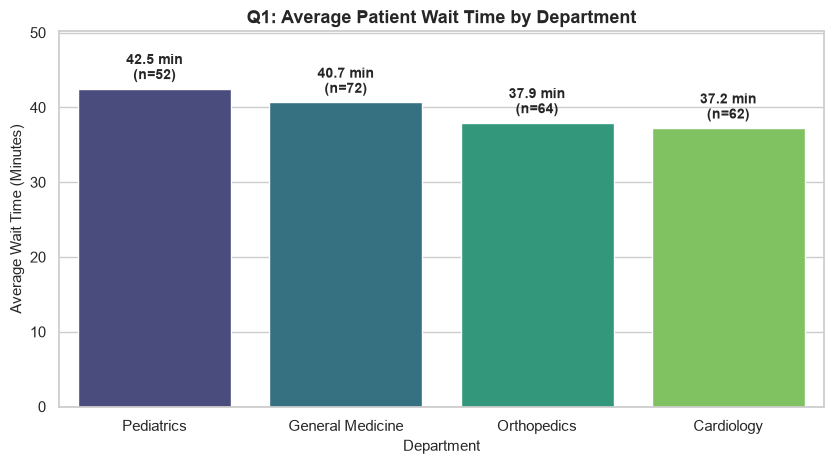

In [8]:
q1_dept = (
    df.groupby("Department", as_index=False)
    .agg(
        Patient_Count=("Patient_ID", "count"),
        Avg_Wait_Mins=("Wait_Time_Minutes", "mean"),
        Median_Wait_Mins=("Wait_Time_Minutes", "median"),
        Avg_Consult_Mins=("Consultation_Minutes", "mean"),
        Avg_Bill_INR=("Bill_Amount_INR", "mean"),
        Avg_Satisfaction=("Satisfaction_Score", "mean")
    )
    .sort_values(by="Avg_Wait_Mins", ascending=False)
    .round(2)
)
display(q1_dept)

plt.figure(figsize=(8.5, 4.8))
ax = sns.barplot(data=q1_dept, x="Department", y="Avg_Wait_Mins", hue="Department", palette="viridis", legend=False)
plt.title("Q1: Average Patient Wait Time by Department")
plt.xlabel("Department")
plt.ylabel("Average Wait Time (Minutes)")
plt.ylim(0, q1_dept["Avg_Wait_Mins"].max() * 1.18)

for p, (_, row) in zip(ax.patches, q1_dept.iterrows()):
    ax.annotate(
        f"{row['Avg_Wait_Mins']:.1f} min\n(n={int(row['Patient_Count'])})",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center", va="bottom", fontsize=10, fontweight="bold", xytext=(0, 4), textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("images/q1_avg_wait_by_department.png", dpi=150)
plt.show()

,Admission_Type,Patient_Count,Avg_Wait_Mins,Median_Wait_Mins,Long_Wait_Pct,Avg_Satisfaction
2,Walk-In,86,57.28,53.0,58.14,5.80
1,Planned,90,32.88,30.5,27.78,6.81
0,Emergency,74,26.88,26.5,18.92,7.22


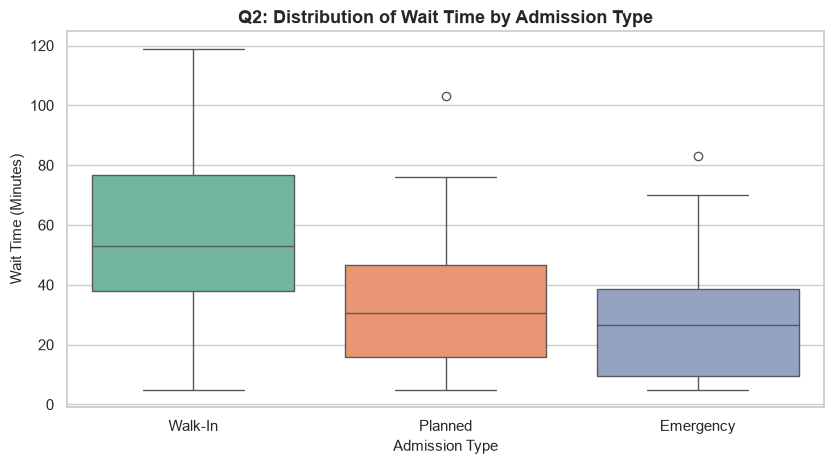

In [9]:
q2_adm = (
    df.groupby("Admission_Type", as_index=False)
    .agg(
        Patient_Count=("Patient_ID", "count"),
        Avg_Wait_Mins=("Wait_Time_Minutes", "mean"),
        Median_Wait_Mins=("Wait_Time_Minutes", "median"),
        Long_Wait_Pct=("Long_Wait", lambda s: (s == "Yes").mean() * 100),
        Avg_Satisfaction=("Satisfaction_Score", "mean")
    )
    .sort_values(by="Avg_Wait_Mins", ascending=False)
    .round(2)
)
display(q2_adm)

plt.figure(figsize=(8.5, 4.8))
order_adm = q2_adm["Admission_Type"].tolist()
sns.boxplot(data=df, x="Admission_Type", y="Wait_Time_Minutes", order=order_adm, hue="Admission_Type", hue_order=order_adm, palette="Set2", legend=False)
plt.title("Q2: Distribution of Wait Time by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Wait Time (Minutes)")
plt.tight_layout()
plt.savefig("images/q2_wait_by_admission_type.png", dpi=150)
plt.show()

,Wait_Time_Level,Patient_Count,Avg_Wait_Mins,Avg_Satisfaction,Median_Satisfaction
1,Low (< 25m),73,12.08,7.74,8.0
2,Medium (25-45m),93,34.71,6.69,7.0
0,High (> 45m),84,68.62,5.46,6.0


Pearson correlation (Wait_Time_Minutes vs. Satisfaction_Score): r = -0.5006


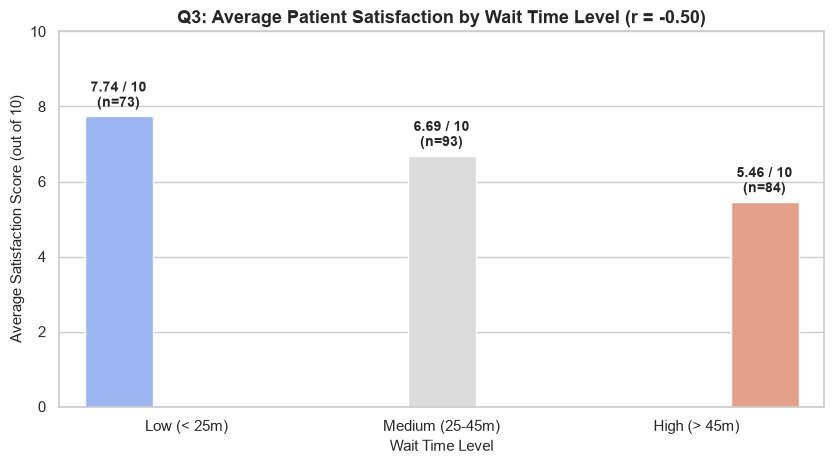

In [10]:
level_order = ["Low (< 25m)", "Medium (25-45m)", "High (> 45m)"]
q3_wait = (
    df.groupby("Wait_Time_Level", as_index=False)
    .agg(
        Patient_Count=("Patient_ID", "count"),
        Avg_Wait_Mins=("Wait_Time_Minutes", "mean"),
        Avg_Satisfaction=("Satisfaction_Score", "mean"),
        Median_Satisfaction=("Satisfaction_Score", "median")
    )
)
q3_wait["Wait_Time_Level"] = pd.Categorical(q3_wait["Wait_Time_Level"], categories=level_order, ordered=True)
q3_wait = q3_wait.sort_values("Wait_Time_Level").round(2)
display(q3_wait)

r_wait_sat = df["Wait_Time_Minutes"].corr(df["Satisfaction_Score"])
print(f"Pearson correlation (Wait_Time_Minutes vs. Satisfaction_Score): r = {r_wait_sat:.4f}")

plt.figure(figsize=(8.5, 4.8))
ax = sns.barplot(data=q3_wait, x="Wait_Time_Level", y="Avg_Satisfaction", hue="Wait_Time_Level", palette="coolwarm", legend=False)
plt.title(f"Q3: Average Patient Satisfaction by Wait Time Level (r = {r_wait_sat:.2f})")
plt.xlabel("Wait Time Level")
plt.ylabel("Average Satisfaction Score (out of 10)")
plt.ylim(0, 10)

for p, (_, row) in zip(ax.patches, q3_wait.iterrows()):
    ax.annotate(
        f"{row['Avg_Satisfaction']:.2f} / 10\n(n={int(row['Patient_Count'])})",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center", va="bottom", fontsize=10, fontweight="bold", xytext=(0, 4), textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("images/q3_satisfaction_by_wait_level.png", dpi=150)
plt.show()

,Age_Group,Patient_Count,Avg_Wait_Mins,Median_Wait_Mins,Avg_Bill_INR,Avg_Satisfaction
0,Under 30,89,42.15,38.0,1225.84,6.61
1,30 to 44,61,38.70,36.0,2064.75,6.70
2,45 to 59,60,38.95,34.0,1877.67,6.82
3,60 and above,40,35.62,26.5,1796.75,6.00


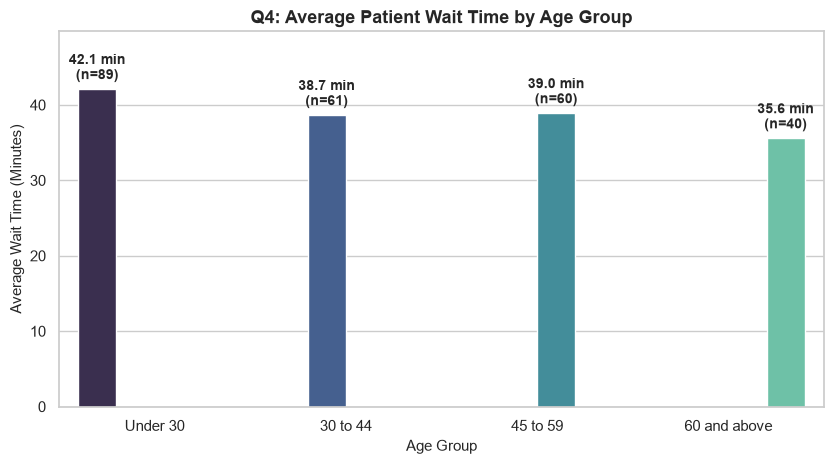

In [11]:
q4_age = (
    df.groupby("Age_Group", observed=False, as_index=False)
    .agg(
        Patient_Count=("Patient_ID", "count"),
        Avg_Wait_Mins=("Wait_Time_Minutes", "mean"),
        Median_Wait_Mins=("Wait_Time_Minutes", "median"),
        Avg_Bill_INR=("Bill_Amount_INR", "mean"),
        Avg_Satisfaction=("Satisfaction_Score", "mean")
    )
    .round(2)
)
display(q4_age)

plt.figure(figsize=(8.5, 4.8))
ax = sns.barplot(data=q4_age, x="Age_Group", y="Avg_Wait_Mins", hue="Age_Group", palette="mako", legend=False)
plt.title("Q4: Average Patient Wait Time by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Wait Time (Minutes)")
plt.ylim(0, q4_age["Avg_Wait_Mins"].max() * 1.18)

for p, (_, row) in zip(ax.patches, q4_age.iterrows()):
    ax.annotate(
        f"{row['Avg_Wait_Mins']:.1f} min\n(n={int(row['Patient_Count'])})",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center", va="bottom", fontsize=10, fontweight="bold", xytext=(0, 4), textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("images/q4_avg_wait_by_age_group.png", dpi=150)
plt.show()

,City,Visits,Avg_Wait_Mins,Avg_Bill_INR,Avg_Satisfaction
3,Mumbai,60,33.12,1746.33,6.58
4,Pune,52,38.02,1687.31,6.60
1,Delhi,48,39.29,1617.50,6.73
2,Lucknow,46,41.70,1647.17,6.72
0,Bengaluru,44,47.86,1673.86,6.27


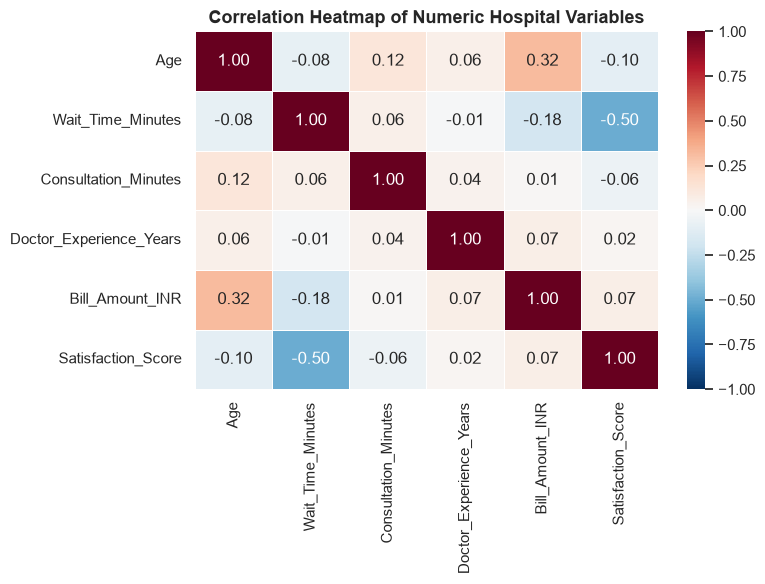

In [12]:
city_summary = (
    df.groupby("City", as_index=False)
    .agg(
        Visits=("Patient_ID", "count"),
        Avg_Wait_Mins=("Wait_Time_Minutes", "mean"),
        Avg_Bill_INR=("Bill_Amount_INR", "mean"),
        Avg_Satisfaction=("Satisfaction_Score", "mean")
    )
    .sort_values(by="Visits", ascending=False)
    .round(2)
)
display(city_summary)

num_cols = ["Age", "Wait_Time_Minutes", "Consultation_Minutes", "Doctor_Experience_Years", "Bill_Amount_INR", "Satisfaction_Score"]
corr_matrix = df[num_cols].corr().round(2)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="RdBu_r", vmin=-1, vmax=1, center=0, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Hospital Variables")
plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=150)
plt.show()

In [13]:
output_csv = "data/processed/healthcare_data_cleaned.csv"
df.to_csv(output_csv, index=False)

print(f"Saved cleaned dataset to: {output_csv} ({df.shape[0]} rows × {df.shape[1]} columns)")
print("Saved charts in 'images/':", sorted(os.listdir("images")))

Saved cleaned dataset to: data/processed/healthcare_data_cleaned.csv (250 rows × 16 columns)
Saved charts in 'images/': ['correlation_heatmap.png', 'q1_avg_wait_by_department.png', 'q2_wait_by_admission_type.png', 'q3_satisfaction_by_wait_level.png', 'q4_avg_wait_by_age_group.png']
